This notebook shows how to use python scripts to extract data points from a model with an arbitrary grid at the locations and times of the sea ice thickness CDR https://psc.apl.uw.edu/sea_ice_cdr/ and compare them.

Steps:
1. Extract model ice thickness and snow depth at all CDR observations (one step, ~1-2 min per model run).
2. Read the extracted data, compute thickness/draft for all observations (`toThick`), and compare by source, region and season.

In [1]:
import logging
import os
import sys

sys.path.append("/home/axel/ax_python_lib/im")
sys.path.append("/home/axel/ax_python_lib/thickCDR/")
sys.path.append("/home/axel/ax_python_lib/axel_utilities")
import axutil
# various utilities for model data manipulation
import ax_im_utils as im

# load routines from the match_thickCDR_model library
from match_thickCDR_model import *

%load_ext autoreload
%autoreload 2

import pandas as pd
pd.set_option('display.float_format','{:.2f}'.format)
logging.basicConfig(stream=sys.stdout, level=logging.INFO)

ERROR 1: PROJ: proj_create_from_database: Open of /home/axel/miniforge3/envs/pangeo312_m2/share/proj failed


## Choose the model run

Model runs are defined in `RUNS` in `match_thickCDR_model.py`: grid, model directory, file variables (`['hiday','snowday']` daily or `['heff','snow']` monthly) and the maximum distance [km] between an observation and the closest model grid cell.

In [2]:
model_id = "2sstC"  # current public PIOMAS run
run = RUNS[model_id]
gridName = run["gridName"]
run

{'gridName': '360X120',
 'model_group': '360X120',
 'dist_thresh': 25.0,
 'nt': 47,
 'file_varnames': ['hiday', 'snowday']}

A run that isn't in `RUNS` yet can be added here (or better, in `match_thickCDR_model.py` so it's kept). The model path defaults to `/data/axel0/model_results/<model_group>/<model_id>/nc/`, or set `model_path`:

```python
RUNS["myrun"] = dict(gridName="360X120", model_group="", dist_thresh=25.0, nt=46,
                     file_varnames=["hiday", "snowday"], model_path="/data/axel0/model_results/myrun/nc/")
```

## Extract model data at the CDR observations

Writes `extractDir/<gridName>/<model_id>/<model_id>.extract.<var0>.<var1>.nc` with all sources. Set `extract = True` to (re)run it; it's only needed once per model run (or when the CDR file changes). The same thing from the command line: `python match_thickCDR_model.py <model_id>`.

Observations are matched to the closest grid cell that has model data (within `dist_thresh`) and the closest model time (within 15 days; monthly fields are centered on mid-month).

In [3]:
extract = False
cdr_file = "/home/axel/projects/sea_ice_cdr/idl/axel_cdr/ncdf_dir/uThickCDR_summaries.20251010_V1.0.nc"
if extract:
    driver_onepass(model_id, cdr_file=cdr_file)

## Read the extracted data and compute thickness and draft

The CDR contains draft, thickness and ice+snow thickness, depending on source. `toThick` fills in the others using the model snow depth, and removes the 0.29 m submarine draft bias. It returns a new data set and is safe to call twice.

In [4]:
obsAndModel = readMerged(model_id, gridName)  # all sources; sources=[...] to select
obsAndModel.load()
obsAndModel = toThick(obsAndModel)
print(obsAndModel.sizes["cdr_index"], "matched observations")

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/360X120/2sstC/2sstC.extract.hiday.snowday.nc


INFO:httpx:HTTP Request: GET https://raw.githubusercontent.com/IrishMarineInstitute/awesome-erddap/master/erddaps.json "HTTP/1.1 200 OK"


1919
INFO:root:Removing Submarine Bias


before bias removal: : 2.8513913
After bias removal: : 2.5613914
427791
INFO:root:Number of missing Draft values : 24966


INFO:root:Number of missing THICK values : 24966


INFO:root:Number of missing THICK_ICE_SNOW values : 24966



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]
454152 matched observations


## Statistics by source

CryoSat-AWI is ~90% of all matched observations, so the `ALL` row is dominated by it.

In [5]:
source_stats(obsAndModel)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.25,1.98,-0.27,0.95,0.61
AWI-GS,134,1.10,0.80,-0.30,0.80,0.50
BGEP,693,1.34,1.55,0.21,0.42,0.89
BIO_LS,36,0.92,1.33,0.41,0.81,0.45
CanCoast,1361,1.28,1.99,0.71,1.21,0.35
CryoSat-AWI,391416,1.29,1.45,0.16,0.51,0.79
Davis_St,67,0.75,0.43,-0.32,0.63,0.75
ICESAT1-G,29244,1.91,2.02,0.11,0.87,0.52
IOS-CHK,26,1.28,1.50,0.23,0.38,0.94
IOS-EBS,382,1.40,1.46,0.06,0.79,0.66


Draft comparison (model draft computed from model thickness and snow):

In [6]:
source_stats(obsAndModel, draft=True)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1395,2.43,2.19,-0.24,0.86,0.78
AWI-GS,134,1.03,1.08,0.05,0.93,0.51
BGEP,693,1.24,1.72,0.48,0.69,0.86
BIO_LS,36,0.88,1.65,0.77,1.09,0.50
CanCoast,1361,1.98,2.63,0.64,1.09,0.81
CryoSat-AWI,391416,1.59,1.74,0.15,0.46,0.87
Davis_St,67,0.69,0.53,-0.17,0.55,0.67
ICESAT1-G,29244,2.33,2.43,0.10,0.79,0.67
IOS-CHK,26,1.20,1.76,0.57,0.67,0.92
IOS-EBS,382,1.29,1.57,0.28,0.88,0.65


## Compare several model runs

Bias (model - observation) by source for runs that have been extracted.

In [7]:
runs = ["2sstC", "1c", "2c", "2cfs"]  # 2sstC = public PIOMAS
tables = {}
for mid in runs:
    ds = readMerged(mid, RUNS[mid]["gridName"])
    ds.load()
    tables[mid] = source_stats(toThick(ds))
pd.concat({mid: t[["n", "bias(mod-obs)", "rmse", "r"]] for mid, t in tables.items()}, axis=1)

Reading data from  /home/axel/ax_python_lib/thickCDR/extractDir/
INFO:root:Reading one-pass extraction /home/axel/ax_python_lib/thickCDR/extractDir/360X120/2sstC/2sstC.extract.hiday.snowday.nc


1919
INFO:root:Removing Submarine Bias


before bias removal: : 2.8513913
After bias removal: : 2.5613914
427791
INFO:root:Number of missing Draft values : 24966


INFO:root:Number of missing THICK values : 24966


INFO:root:Number of missing THICK_ICE_SNOW values : 24966



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]


... (15 outputs left out)

INFO:root:Number of missing THICK values : 25071


INFO:root:Number of missing THICK_ICE_SNOW values : 25071



Coordinates of Missing Values:
cdr_index: [ 2520000  2520005  2520006 ... 21025034 21025035 21025036]


2sstC                              1c                          \
                   n bias(mod-obs) rmse    r       n bias(mod-obs) rmse    r   
AIR-EM          1395         -0.27 0.95 0.61    1229          1.07 1.51 0.67   
AWI-GS           134         -0.30 0.80 0.50     134          0.90 1.17 0.49   
BGEP             693          0.21 0.42 0.89     693          0.73 0.86 0.82   
BIO_LS            36          0.41 0.81 0.45      36          0.57 1.02 0.29   
CanCoast        1361          0.71 1.21 0.35     776          1.06 1.50 0.25   
CryoSat-AWI   391416          0.16 0.51 0.79  381652          0.88 1.14 0.73   
Davis_St          67         -0.32 0.63 0.75      67          0.10 0.52 0.75   
ICESAT1-G      29244          0.11 0.87 0.52   29220          0.93 1.31 0.63   
IOS-CHK           26          0.23 0.38 0.94      26          0.62 0.70 0.94   
IOS-EBS          382          0.06 0.79 0.66     382          0.23 1.02 0.56   
IceBridge-QL    1517         -0.21 0.78 0.68    1517          0.80 1.11 0.74   
IceBridge-V2     932         -0.33 0.96 0.42     933          0.90 1.42 0.55   
NPEO              64         -1.01 1.27 0.52      64          0.02 0.91 0.22   
UKSUB-AN         149         -0.36 1.54 0.61     149          1.02 1.88 0.59   
USSUB-AN         646         -0.36 0.79 0.80     646         -0.06 0.72 0.77   
USSUB-DG        1124         -0.08 0.74 0.71    1122          0.02 0.83 0.66   
ALL           429186          0.16 0.56 0.77  418646          0.88 1.15 0.73   

                    2c                            2cfs                          
                     n bias(mod-obs) rmse    r       n bias(mod-obs) rmse    r  
AIR-EM         1224.00          0.22 0.96 0.70    1395         -0.10 0.91 0.63  
AWI-GS             NaN           NaN  NaN  NaN     134         -0.49 0.74 0.59  
BGEP            693.00          0.31 0.57 0.82     693          0.64 0.74 0.87  
BIO_LS           36.00          0.01 0.57 0.69      36          0.36 0.70 0.68  
CanCoast        125.00          1.92 2.33 0.27    1522          0.71 1.81 0.16  
CryoSat-AWI  381652.00          0.51 0.76 0.76  402251          0.44 0.70 0.74  
Davis_St         67.00          0.01 0.52 0.75      67         -0.12 0.50 0.78  
ICESAT1-G     29220.00          0.39 0.98 0.55   29393          0.17 0.95 0.36  
IOS-CHK          26.00          0.26 0.40 0.96      26          0.50 0.62 0.92  
IOS-EBS           9.00         -0.47 1.04 0.34     382          0.07 0.78 0.65  
IceBridge-QL   1517.00          0.23 0.77 0.73    1518         -0.09 0.82 0.60  
IceBridge-V2    933.00          0.25 0.95 0.57     933         -0.17 0.89 0.46  
NPEO             43.00         -0.62 1.12 0.43      64         -1.00 1.31 0.32  
UKSUB-AN           NaN           NaN  NaN  NaN     149         -1.09 1.85 0.69  
USSUB-AN         58.00         -0.14 0.56 0.85     646         -0.54 1.01 0.67  
USSUB-DG        121.00          0.49 0.63 0.55    1124         -0.40 0.97 0.52  
ALL          415724.00          0.50 0.78 0.75  440333          0.42 0.73 0.71

## Scatter plot and histograms for observed and modeled ice thickness

Model has Nan:  False
Observations have Nan: False
[0.44382238 0.78299092]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.621
Model:                            OLS   Adj. R-squared:                  0.621
Method:                 Least Squares   F-statistic:                 6.420e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:29:54   Log-Likelihood:            -2.5018e+05
No. Observations:              391416   AIC:                         5.004e+05
Df Residuals:                  391414   BIC:                         5.004e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

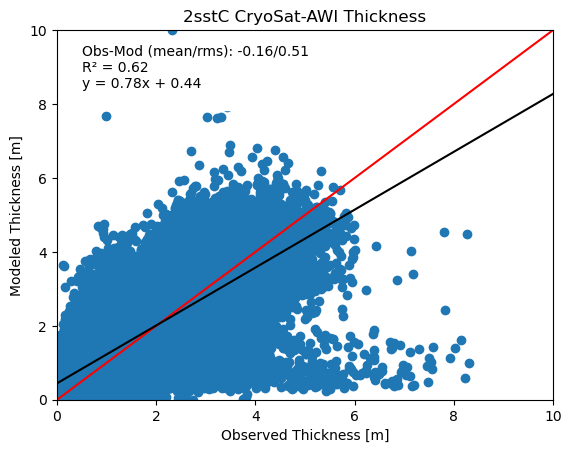

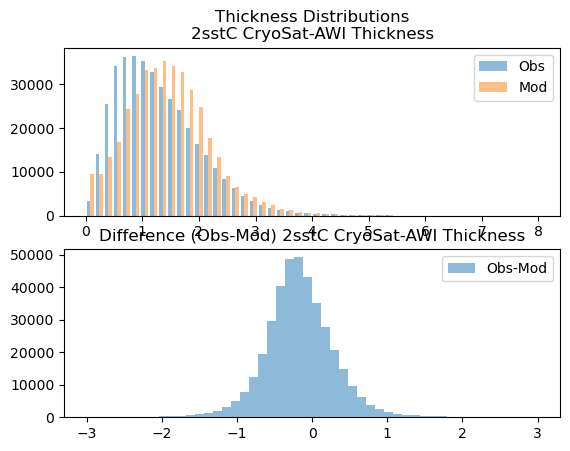

In [8]:
select_sources = ["CryoSat-AWI"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Thickness"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=False)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Same for draft

Model has Nan:  False
Observations have Nan: False
[0.22600686 1.20207313]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.736
Model:                            OLS   Adj. R-squared:                  0.735
Method:                 Least Squares   F-statistic:                     1922.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          8.75e-202
Time:                        12:29:55   Log-Likelihood:                -482.23
No. Observations:                 693   AIC:                             968.5
Df Residuals:                     691   BIC:                             977.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

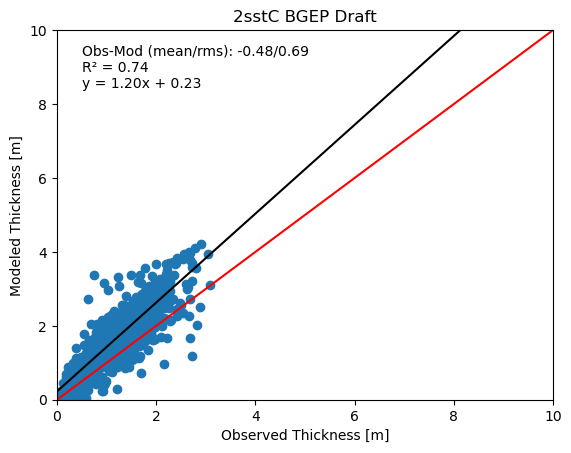

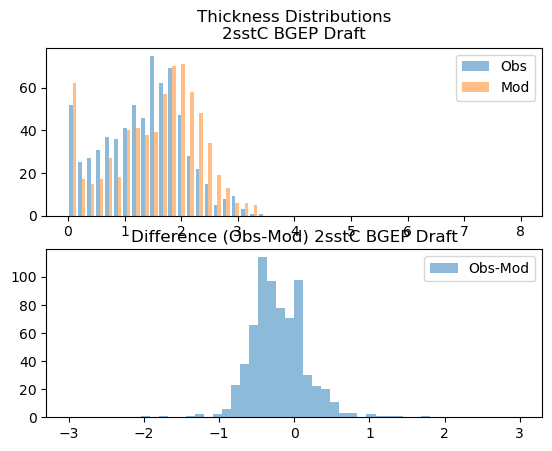

In [9]:
select_sources = ["BGEP"]
sub = obsAndModel.isel(cdr_index=obsAndModel.SOURCE.isin(select_sources).values)
title = model_id + " " + ":".join(select_sources) + " Draft"
fig, ax, results = scatter_plot(sub, model_id, title=title, draft=True)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Demonstrate how subsetting by space can be done

In [10]:
import geopandas as gpd
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature 
from shapely.geometry import Point,MultiPoint,Polygon, mapping
from model_maps_arctic import map_arctic_ortho,map_arctic_region,arctic_map_outline,ax_reset_norm

Remove the satellite sources (they dominate by number) and keep the mean values (`Mean Max Min Sigma` = 0), which is necessary for creating the pandas data frame.

In [11]:
satellite = ["CryoSat-AWI", "ENVISAT", "ICESAT1-G"]
insitu = obsAndModel.isel(cdr_index=~obsAndModel.SOURCE.isin(satellite).values)
sub = insitu.isel({"Mean Max Min Sigma": 0})
sub["lon"] = axutil.lonTo180(sub.lon)  # appears necessary otherwise doesn't work.
df = sub.to_dataframe()
geometry = gpd.points_from_xy(df["lon"], df["lat"])

## Create a geopanda data frame from the geometry data created above

In [12]:
gdf_points = gpd.GeoDataFrame(df,geometry=geometry, crs="EPSG:4326")

## Now define a Polygon in Lon,lat Space and create a geopanda polygon 

In [13]:
polygon = Polygon([(-100, 70), (-100, 82), (-180, 82), (-180, 70)])
gdf_polygon = gpd.GeoDataFrame(geometry=[polygon], crs="EPSG:4326")

## Check if the list of points (cdr observations) is inside the polygon defined above

In [14]:
points_within_polygon = gpd.sjoin(gdf_points, gdf_polygon, predicate='within')

## For checking that the subsetting works, plot the area that is selected

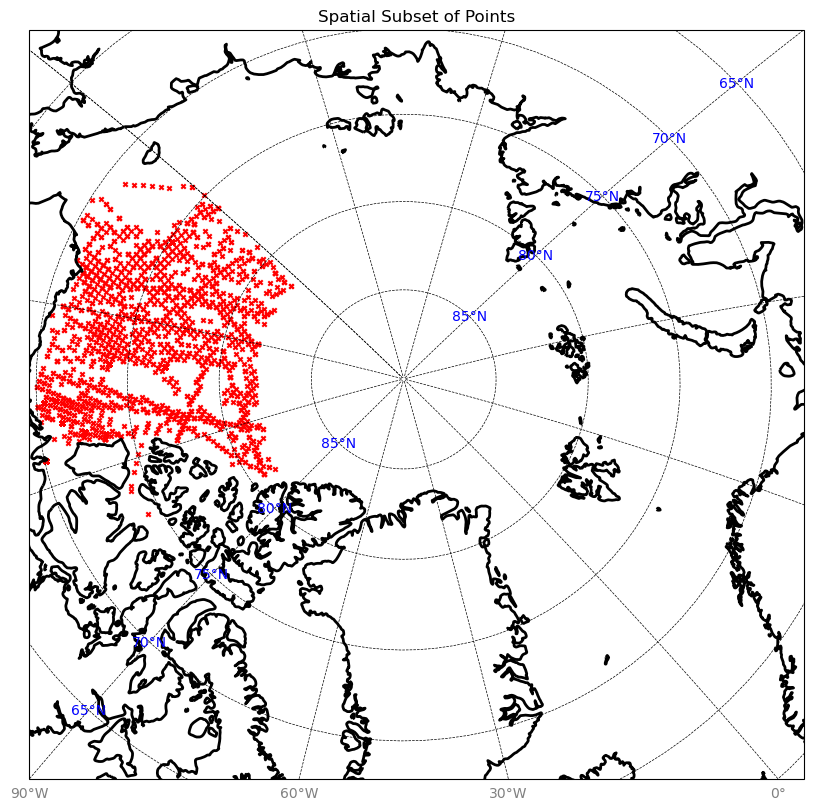

In [15]:
ax,fig,gl=arctic_map_outline("Spatial Subset of Points",land_fill=False)
plons=points_within_polygon['geometry'].x
plats=points_within_polygon['geometry'].y
ax.scatter(x=plons,y=plats,s=10,marker='x',color='red',transform=ccrs.PlateCarree())
plt.show()

## Now create the scatter plot and histogram of the subset

Model has Nan:  False
Observations have Nan: False
[0.81016081 0.62359915]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.561
Model:                            OLS   Adj. R-squared:                  0.561
Method:                 Least Squares   F-statistic:                     4109.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:29:59   Log-Likelihood:                -2529.4
No. Observations:                3212   AIC:                             5063.
Df Residuals:                    3210   BIC:                             5075.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

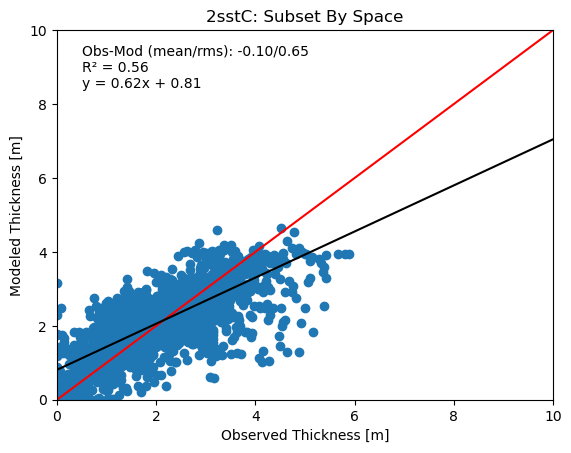

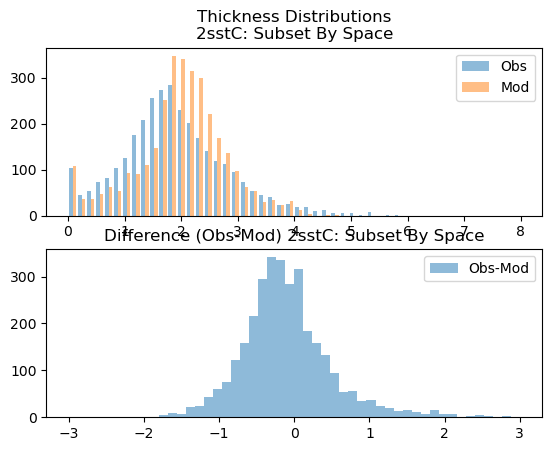

In [16]:
title = model_id + ": Subset By Space"
cdr_index = points_within_polygon.index
sub = insitu.sel(cdr_index=cdr_index)
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

## Winter and summer

Model has Nan:  False
Observations have Nan: False
[1.3279931  0.43427489]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     1307.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          4.99e-221
Time:                        12:30:00   Log-Likelihood:                -1324.4
No. Observations:                2015   AIC:                             2653.
Df Residuals:                    2013   BIC:                             2664.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

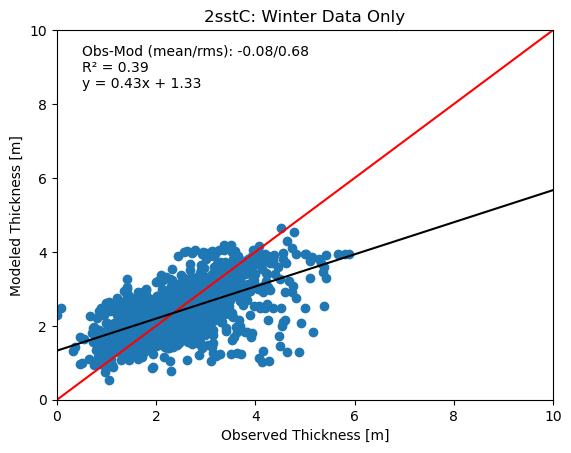

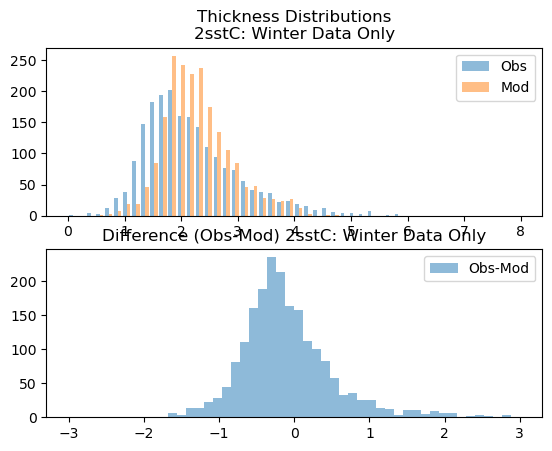

In [17]:
def is_winter(month):
    return (month >= 1) & (month <= 4)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_winter(sub["obs_time.month"]))
title = model_id + ": Winter Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Model has Nan:  False
Observations have Nan: False
[0.45720031 0.75344193]
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.620
Model:                            OLS   Adj. R-squared:                  0.619
Method:                 Least Squares   F-statistic:                     1778.
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          2.05e-231
Time:                        12:30:00   Log-Likelihood:                -895.25
No. Observations:                1094   AIC:                             1795.
Df Residuals:                    1092   BIC:                             1805.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

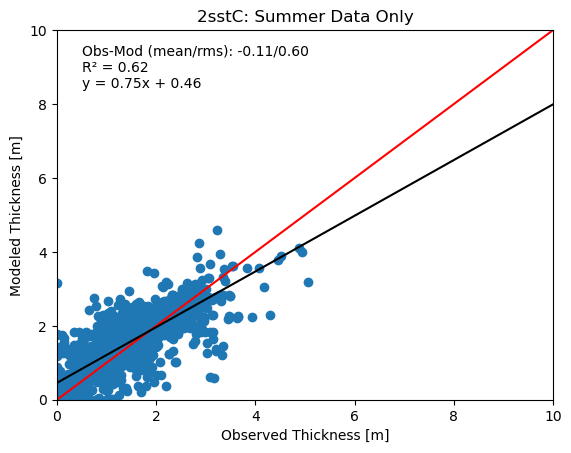

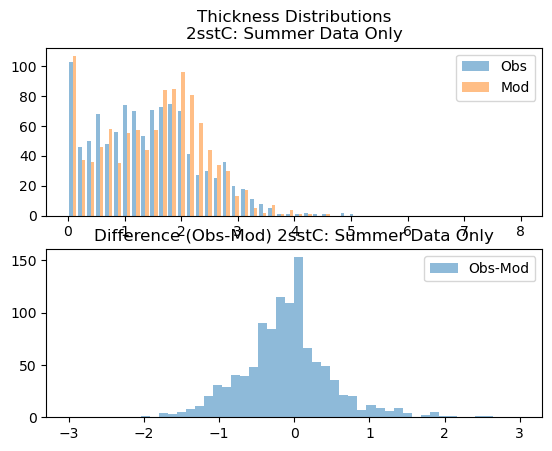

In [18]:
def is_summer(month):
    return (month >= 5) & (month <= 11)

sub = insitu.sel(cdr_index=cdr_index)
sub = sub.isel(cdr_index=is_summer(sub["obs_time.month"]))
title = model_id + ": Summer Data Only"
fig, ax, results = scatter_plot(sub, model_id, title=title)
fig, ax0, ax1 = plot_histograms(sub, model_id, title=title)

Statistics by source for the summer subset:

In [19]:
source_stats(sub)

,n,obs_mean,mod_mean,bias(mod-obs),rmse,r
AIR-EM,1,5.06,3.17,-1.89,1.89,NaN
BGEP,410,1.15,1.26,0.11,0.41,0.88
CanCoast,47,1.27,1.17,-0.10,0.41,0.82
IOS-CHK,16,0.96,1.25,0.28,0.41,0.95
IOS-EBS,228,1.26,1.16,-0.10,0.77,0.71
USSUB-AN,184,1.78,2.04,0.26,0.66,0.79
USSUB-DG,208,1.76,2.03,0.27,0.69,0.71
ALL,1094,1.40,1.51,0.11,0.60,0.79
